# 02 — Regimenes globales
**Objetivo:**: Bajar las series de 4.1, guardarlas en `data/raw`, pasarlas a frecuencia **mensual**, alinear, tratar faltantes.
Features: inflación interanual, cambio de desempleo a 12m, curva, spread, VIX, NFCI. Estandarizar (z-score).
**Conceptos:** pandas, resampling, transformaciones (niveles vs. cambios), estacionariedad, correlaciones.
**Listo cuando:** hay un `features_global.parquet` mensual y gráficos de cada feature con recesiones marcadas.
**Conclusiones:** 

In [23]:
%load_ext autoreload
%autoreload 2          
import sys; sys.path.append("..") 

from src.data import fred as fd
from src.features import build as build

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
series = fd.bajar_todas()                  # baja las 16 series
mensual = build.panel_mensual(series)      # las pasa a mensual
p = build.agregar_sustitutos(mensual)      # le suma las 2 columnas nuevas

#print(completo.index.min(), "→", completo.index.max(), "| filas completas:", len(completo))

T10Y2Y | 1976-06-01 00:00:00 → 2026-11-27 00:00:00 | 13174 | 555
T10Y3M | 1982-01-04 00:00:00 → 2026-11-27 00:00:00 | 11715 | 487
DGS2 | 1976-06-01 00:00:00 → 2026-11-25 00:00:00 | 13172 | 554
DGS10 | 1962-01-02 00:00:00 → 2026-11-25 00:00:00 | 16932 | 722
FEDFUNDS | 1954-07-01 00:00:00 → 2026-10-01 00:00:00 | 868 | 0
CPIAUCSL | 1947-01-01 00:00:00 → 2026-10-01 00:00:00 | 958 | 1
UNRATE | 1948-01-01 00:00:00 → 2026-10-01 00:00:00 | 946 | 1
INDPRO | 1919-01-01 00:00:00 → 2026-10-01 00:00:00 | 1294 | 0
BAA10Y | 1986-01-02 00:00:00 → 2026-11-24 00:00:00 | 10669 | 445
NFCI | 1971-01-08 00:00:00 → 2026-11-20 00:00:00 | 2916 | 0
VIXCLS | 1990-01-02 00:00:00 → 2026-11-26 00:00:00 | 9628 | 302
DTWEXBGS | 2006-01-02 00:00:00 → 2026-11-20 00:00:00 | 5450 | 214
USREC | 1854-12-01 00:00:00 → 2026-10-01 00:00:00 | 2063 | 0
GS10 | 1953-04-01 00:00:00 → 2026-10-01 00:00:00 | 883 | 0
TB3MS | 1934-01-01 00:00:00 → 2026-10-01 00:00:00 | 1114 | 0
BAA | 1919-01-01 00:00:00 → 2026-10-01 00:00:00 | 1294 | 0

                     T10Y3M  CURVA_10Y3M_LARGA
T10Y3M             1.000000           0.999869
CURVA_10Y3M_LARGA  0.999869           1.000000


<Axes: title={'center': 'Curva 10a−3m: oficial vs. sustituta'}>

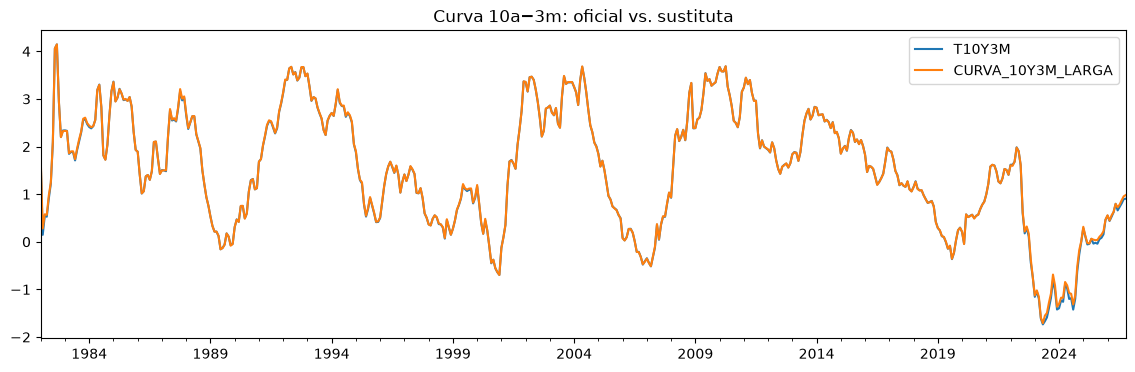

In [29]:
par = p[["T10Y3M", "CURVA_10Y3M_LARGA"]].dropna()
print(par.corr())

par.plot(figsize=(14, 4), title="Curva 10a−3m: oficial vs. sustituta")

count    538.000000
mean       0.009072
std        0.021848
min       -0.024336
25%       -0.001965
50%        0.002717
75%        0.010360
max        0.134535
dtype: float64


<Axes: title={'center': 'Curva sustituta − oficial'}>

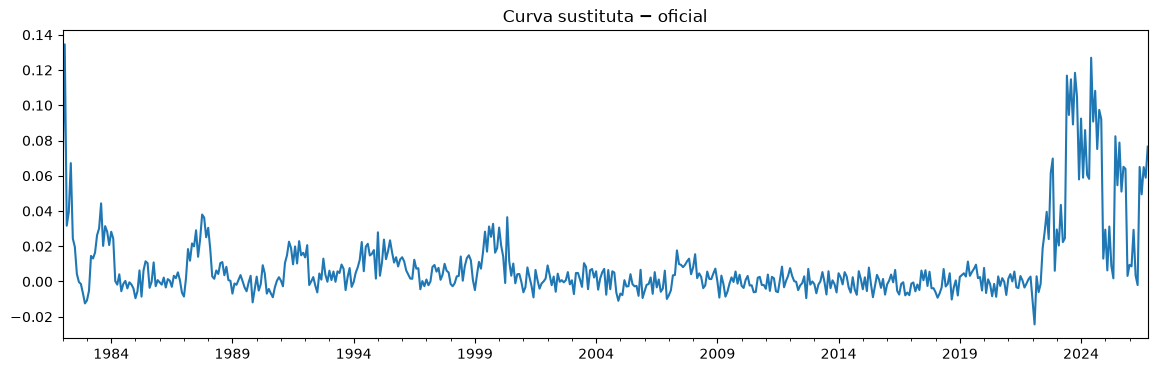

In [30]:
par = p[["T10Y3M", "CURVA_10Y3M_LARGA"]].dropna()
diff = par.iloc[:, 1] - par.iloc[:, 0]
print(diff.describe())
diff.plot(figsize=(14, 4), title="Curva sustituta − oficial")